<a href="https://colab.research.google.com/github/KritiMagar/CSC425_spam_detection/blob/main/CSC425_Milestone2_Spam_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import urllib.request
import zipfile
import os

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# Download UCI SMS Spam Collection dataset directly
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam.zip"
urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("sms_data")

# Load tab-separated dataset
df = pd.read_csv("sms_data/SMSSpamCollection", sep='\t', names=['label', 'message'])
print("Raw Dataset Shape:", df.shape)
print(df.head())

Raw Dataset Shape: (5572, 2)
  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...


Number of duplicate messages found: 403
Cleaned Dataset Shape: (5169, 2)

Class Distribution after dropping duplicates:
       Count  Percentage (%)
label                       
ham     4516       87.366996
spam     653       12.633004


/tmp/ipykernel_4780/236093661.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette='Blues_d')


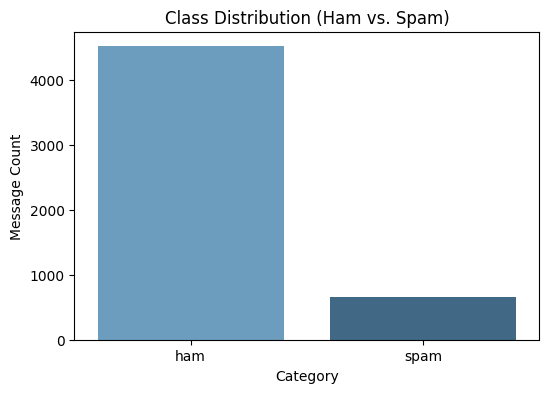

In [2]:
# 1. Check & Drop Duplicates
duplicates_count = df.duplicated().sum()
print(f"Number of duplicate messages found: {duplicates_count}")
df = df.drop_duplicates().reset_index(drop=True)
print(f"Cleaned Dataset Shape: {df.shape}")

# 2. Binary Label Encoding (ham = 0, spam = 1)
df['target'] = df['label'].map({'ham': 0, 'spam': 1})

# 3. Class Imbalance Check
class_counts = df['label'].value_counts()
class_percentages = df['label'].value_counts(normalize=True) * 100
print("\nClass Distribution after dropping duplicates:")
print(pd.DataFrame({'Count': class_counts, 'Percentage (%)': class_percentages}))

# Plot Class Distribution
plt.figure(figsize=(6, 4))
sns.barplot(x=class_counts.index, y=class_counts.values, palette='Blues_d')
plt.title("Class Distribution (Ham vs. Spam)")
plt.ylabel("Message Count")
plt.xlabel("Category")
plt.savefig("class_distribution.png", dpi=300, bbox_inches='tight')
plt.show()

In [3]:
# 1. Stratified Split (80% Train, 20% Test)
X = df['message']
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set size: {len(X_train)} samples")
print(f"Testing set size: {len(X_test)} samples")
print("\nTrain class ratio:\n", y_train.value_counts(normalize=True))
print("\nTest class ratio:\n", y_test.value_counts(normalize=True))

# 2. Fit TF-IDF Vectorizer ONLY on training set (avoids data leakage)
tfidf = TfidfVectorizer(lowercase=True, stop_words='english', max_features=3000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print(f"\nVocabulary size: {len(tfidf.vocabulary_)} features")
print(f"X_train_tfidf shape: {X_train_tfidf.shape}")
print(f"X_test_tfidf shape: {X_test_tfidf.shape}")

Training set size: 4135 samples
Testing set size: 1034 samples

Train class ratio:
 target
0    0.873761
1    0.126239
Name: proportion, dtype: float64

Test class ratio:
 target
0    0.873308
1    0.126692
Name: proportion, dtype: float64

Vocabulary size: 3000 features
X_train_tfidf shape: (4135, 3000)
X_test_tfidf shape: (1034, 3000)


In [4]:
# Baseline 1: Majority Class Dummy ("Always Ham")
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train_tfidf, y_train)
y_pred_dummy = dummy.predict(X_test_tfidf)

# Baseline 2: Multinomial Naive Bayes Prototype
nb_model = MultinomialNB()
nb_model.fit(X_train_tfidf, y_train)
y_pred_nb = nb_model.predict(X_test_tfidf)

# Evaluation Function
def evaluate_model(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, zero_division=0)
    rec = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    return {'Model': name, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1}

results = pd.DataFrame([
    evaluate_model("Majority Class Baseline (Always Ham)", y_test, y_pred_dummy),
    evaluate_model("Multinomial Naive Bayes (Prototype)", y_test, y_pred_nb)
])

print("\n--- MODEL PERFORMANCE COMPARISON ---")
print(results.to_string(index=False))

print("\nDetailed Naive Bayes Classification Report:")
print(classification_report(y_test, y_pred_nb, target_names=['Ham', 'Spam']))


--- MODEL PERFORMANCE COMPARISON ---
                               Model  Accuracy  Precision   Recall  F1-Score
Majority Class Baseline (Always Ham)  0.873308        0.0 0.000000  0.000000
 Multinomial Naive Bayes (Prototype)  0.973888        1.0 0.793893  0.885106

Detailed Naive Bayes Classification Report:
              precision    recall  f1-score   support

         Ham       0.97      1.00      0.99       903
        Spam       1.00      0.79      0.89       131

    accuracy                           0.97      1034
   macro avg       0.99      0.90      0.94      1034
weighted avg       0.97      0.97      0.97      1034



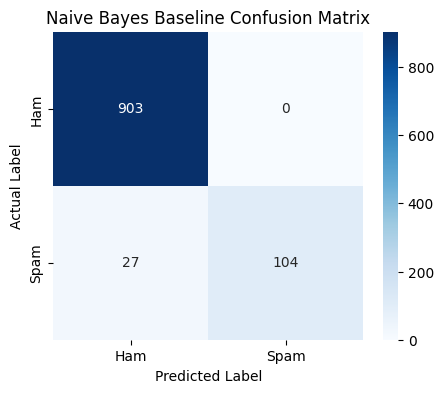


--- SAMPLE PREDICTIONS PIPELINE TEST ---
Message: "Hey Kriti, are we still meeting at the university library at 3 PM?"
Predicted Class: HAM (Legitimate)

Message: "URGENT! You have won a $1,000 Walmart Gift Card. Click here to claim your reward now: http://tinyurl.com/fake-win"
Predicted Class: SPAM (Junk)

Message: "Can you please pick up some milk on your way home tonight?"
Predicted Class: HAM (Legitimate)

Message: "FREE entry into our weekly £1000 prize draw. Text CLAIM to 87121 now to claim your entry!"
Predicted Class: SPAM (Junk)



In [5]:
# Confusion Matrix Plot
cm = confusion_matrix(y_test, y_pred_nb)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Ham', 'Spam'], yticklabels=['Ham', 'Spam'])
plt.title("Naive Bayes Baseline Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.savefig("confusion_matrix_nb.png", dpi=300, bbox_inches='tight')
plt.show()

# Sample Live Predictions
sample_messages = [
    "Hey Kriti, are we still meeting at the university library at 3 PM?",
    "URGENT! You have won a $1,000 Walmart Gift Card. Click here to claim your reward now: http://tinyurl.com/fake-win",
    "Can you please pick up some milk on your way home tonight?",
    "FREE entry into our weekly £1000 prize draw. Text CLAIM to 87121 now to claim your entry!"
]

sample_features = tfidf.transform(sample_messages)
sample_preds = nb_model.predict(sample_features)
labels_map = {0: "HAM (Legitimate)", 1: "SPAM (Junk)"}

print("\n--- SAMPLE PREDICTIONS PIPELINE TEST ---")
for msg, pred in zip(sample_messages, sample_preds):
    print(f"Message: \"{msg}\"")
    print(f"Predicted Class: {labels_map[pred]}\n")